In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!git clone -q https://github.com/hkphd20/Traffic-Data-Set /content/tds
!pip install -q ultralytics opencv-python

import cv2, glob
for p in sorted(glob.glob('/content/tds/sb*')):
    c = cv2.VideoCapture(p)
    n = c.get(cv2.CAP_PROP_FRAME_COUNT)
    fps = c.get(cv2.CAP_PROP_FPS)
    print(p.split('/')[-1], int(c.get(3)), 'x', int(c.get(4)),
          '| fps', fps, '| frames', int(n), '| secs', round(n / max(fps, 1)))

print('--- detector files ---')
!ls /content/tds | grep -i -E "weights|\.pt|cfg|names"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 10.7 MB/s eta 0:00:00
sb1.mp4 2592 x 1944 | fps 5.0 | frames 256 | secs 51
sb2.avi 2592 x 1944 | fps 5.0 | frames 256 | secs 51
sb3.avi 2592 x 1944 | fps 5.0 | frames 256 | secs 51
sb4.mp4 2592 x 1944 | fps 5.0 | frames 256 | secs 51
sb5.avi 2592 x 1944 | fps 5.0 | frames 256 | secs 51
--- detector files ---
coco.names
obj.names
yolo-obj.cfg


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!test -d /content/tds || git clone -q https://github.com/hkphd20/Traffic-Data-Set /content/tds
!pip install -q ultralytics

import os, glob, numpy as np, pandas as pd, torch
from ultralytics import YOLO

OUT = '/content/drive/MyDrive/proj_patched/video_tracks'
os.makedirs(OUT + '/csv', exist_ok=True)
dev = 0 if torch.cuda.is_available() else 'cpu'
print('device:', dev)

model = YOLO('yolov8n.pt')
CLASSES = [0, 1, 2, 3, 5, 7]   # person, bicycle, car, motorcycle, bus, truck
rows = []
for p in sorted(glob.glob('/content/tds/sb*')):
    name = os.path.splitext(os.path.basename(p))[0]
    print('tracking', name, flush=True)
    results = model.track(p, stream=True, persist=True, tracker='bytetrack.yaml',
                          classes=CLASSES, imgsz=1280, conf=0.25,
                          device=dev, verbose=False)
    for f, r in enumerate(results):
        if r.boxes is None or r.boxes.id is None:
            continue
        b = r.boxes.xyxy.cpu().numpy()
        ids = r.boxes.id.cpu().numpy().astype(int)
        cl = r.boxes.cls.cpu().numpy().astype(int)
        for (x1, y1, x2, y2), i, c in zip(b, ids, cl):
            rows.append((name, i, c, f, f / 5.0, (x1 + x2) / 2, y2))

df = pd.DataFrame(rows, columns=['video', 'track', 'cls', 'frame', 't', 'x', 'y'])
df.to_csv(f'{OUT}/all_tracks.csv', index=False)
print(len(df), 'detections |', df.groupby(['video', 'track']).ngroups, 'tracks')

summary = []
for (v, tid), g in df.groupby(['video', 'track']):
    g = g.sort_values('frame')
    span = int(g.frame.max() - g.frame.min() + 1)
    if span < 30:                      # need >= 6 s for the model
        continue
    g[['t', 'x', 'y']].to_csv(f'{OUT}/csv/{v}_id{tid}_cls{g.cls.iloc[0]}.csv', index=False)
    summary.append((v, tid, int(g.cls.iloc[0]), span, span - len(g)))

s = pd.DataFrame(summary, columns=['video', 'track', 'cls', 'span', 'missing_frames'])
print(s.sort_values('span', ascending=False).head(15))
print('tracks >= 30 frames:', len(s), '| fully complete:', int((s.missing_frames == 0).sum()))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
device: 0
tracking sb1
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 244ms
Prepared 1 package in 57ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.6s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

tracking sb2
tracking sb3
tracking sb4
tracking sb5
36170 detections | 1647 tracks
    video  track  cls  span  missing_frames
19    sb1     32    2   256               4
131   sb2   2955    2   255

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import sys, glob, re, numpy as np, pandas as pd
sys.path.insert(0, '/content/drive/MyDrive/proj_patched')
from impute import load_model, make_predictor, simulate, PROFILES

model = load_model('/content/drive/MyDrive/runs/unified_v4.pt')
V = '/content/drive/MyDrive/proj_patched/video_tracks/csv'
files = sorted(glob.glob(V + '/*.csv'))
print(len(files), 'track files')

def cls_of(f):
    return int(re.search(r'_cls(\d+)', f).group(1))

GROUPS = {
    'pedestrian': [f for f in files if cls_of(f) == 0],
    'two-wheeler': [f for f in files if cls_of(f) in (1, 3)],
    'car/bus/truck': [f for f in files if cls_of(f) in (2, 5, 7)],
}
PROF = {
    'Ped profile (px)': 'Pedestrian - IDD-PeD style (pixels)',
    'Car profile': 'Car - HetroD style (metres)',
    'Two-wheeler profile': 'Two-wheeler - I2WDD style (metres)',
}

def agg(fs, prof, gap_s):
    ds, agent = PROFILES[prof]
    pred = make_predictor(model, ds, agent)
    se = dict(model=0.0, hermite=0.0, linear=0.0)
    pts = used = 0
    for f in fs:
        d = pd.read_csv(f)
        if len(d) < 30:
            continue
        try:
            m, _ = simulate(d, pred, ds, gap_s=gap_s, trials=10)
        except ValueError:
            continue
        for k in se:
            se[k] += m['rmse'][k] ** 2 * m['points']
        pts += m['points']
        used += 1
    if pts == 0:
        return None
    r = {k: (v / pts) ** 0.5 for k, v in se.items()}
    return dict(tracks=used, points=pts, model=r['model'],
                hermite=r['hermite'], linear=r['linear'],
                model_vs_hermite_pct=(1 - r['model'] / r['hermite']) * 100)

rows = []
for g, fs in GROUPS.items():
    for pname, prof in PROF.items():
        for gap in (2.0, 3.0):
            r = agg(fs, prof, gap)
            if r:
                rows.append(dict(group=g, profile=pname, gap_s=gap, **r))
res = pd.DataFrame(rows).round(3)
print(res.to_string(index=False))
res.to_csv('/content/drive/MyDrive/proj_patched/video_tracks/eval_video_tracks.csv', index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
562 track files
        group             profile  gap_s  tracks  points  model  hermite  linear  model_vs_hermite_pct
   pedestrian    Ped profile (px)    2.0     212   21050 26.060   15.597  18.293               -67.082
   pedestrian    Ped profile (px)    3.0     200   29640 53.030   22.994  29.742              -130.629
   pedestrian         Car profile    2.0     212   21050 17.006   15.597  18.293                -9.033
   pedestrian         Car profile    3.0     200   29640 30.491   22.994  29.742               -32.606
   pedestrian Two-wheeler profile    2.0     212   21050 18.466   15.597  18.293               -18.398
   pedestrian Two-wheeler profile    3.0     200   29640 35.040   22.994  29.742               -52.392
  two-wheeler    Ped profile (px)    2.0     116   11600 25.739   11.542  13.150              -123.007
  two-wheeler    Ped profile (p

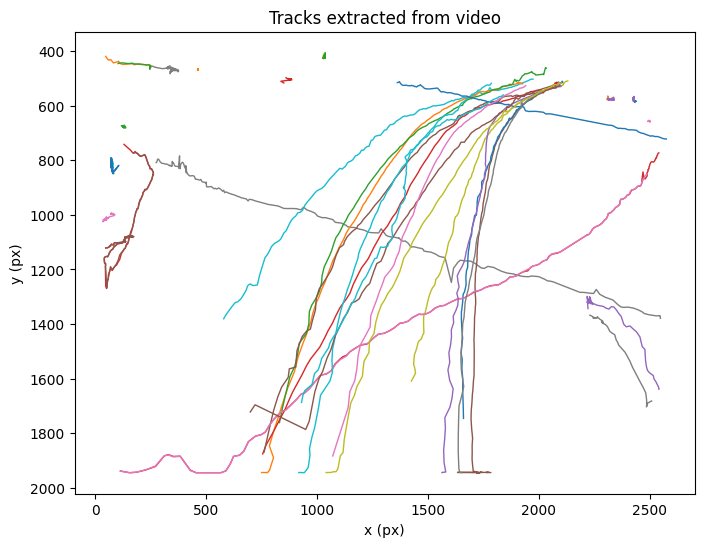

In [ ]:
import matplotlib.pyplot as plt
df = pd.read_csv('/content/drive/MyDrive/proj_patched/video_tracks/all_tracks.csv')
long_ = (df.groupby(['video', 'track']).size().sort_values(ascending=False).head(40).index)
fig, ax = plt.subplots(figsize=(8, 6))
for v, t in long_:
    g = df[(df.video == v) & (df.track == t)]
    ax.plot(g.x, g.y, lw=1)
ax.invert_yaxis()   # image coordinates
ax.set_xlabel('x (px)'); ax.set_ylabel('y (px)'); ax.set_title('Tracks extracted from video')
plt.show()

In [ ]:
import os, shutil
sel = sorted(glob.glob('/content/drive/MyDrive/proj_patched/video_tracks/csv/*.csv'),
             key=lambda f: -len(pd.read_csv(f)))[:5]
dst = '/content/drive/MyDrive/proj_patched/video_tracks/samples'
os.makedirs(dst, exist_ok=True)
for f in sel:
    shutil.copy(f, dst)
print(os.listdir(dst))

['sb2_id2955_cls2.csv', 'sb1_id32_cls2.csv', 'sb2_id2964_cls7.csv', 'sb4_id7383_cls0.csv', 'sb4_id7526_cls2.csv']


In [2]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/proj_patched/proj
!ls -lh finetune_video.py unified_v4.pt unified_tracks.pkl common_schema.py unified_data.py model_unified.py
!ls /content/drive/MyDrive/proj_patched/video_tracks/csv | wc -l

Mounted at /content/drive
/content/drive/MyDrive/proj_patched/proj
-rw------- 1 root root 4.8K Oct 10 05:11 common_schema.py
-rw------- 1 root root 8.7K Oct 10 17:42 finetune_video.py
-rw------- 1 root root 3.3K Oct 10 05:11 model_unified.py
-rw------- 1 root root 8.1K Oct  4 12:51 unified_data.py
-rw------- 1 root root  70M Oct  3 18:15 unified_tracks.pkl
-rw------- 1 root root 3.7M Oct 10 05:11 unified_v4.pt
562


In [2]:
!python finetune_video.py --cache unified_tracks.pkl --video_dir /content/drive/MyDrive/proj_patched/video_tracks/csv --v4 unified_v4.pt --out unified_v7_video.pt

python3: can't open file '/content/drive/MyDrive/proj_patched/proj/finetune_video.py': [Errno 2] No such file or directory


In [3]:
%%writefile /content/drive/MyDrive/proj_patched/proj/finetune_video.py
"""finetune_video.py -- fine-tune v4 on tracks extracted from Sir's traffic videos (+ replay of 4 real datasets)."""
import argparse, copy, glob, os, pickle, sys
import numpy as np, pandas as pd, torch
from torch.utils.data import DataLoader, WeightedRandomSampler

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import common_schema as cs

VIDEO = 5                         # new dataset id (4 is left free for SUMO)
cs.DATASET["video"] = VIDEO
cs.DATASET_NAMES[VIDEO] = "video"
cs.SCALE[VIDEO] = 100.0           # pixels, same scale as IDD-PeD
cs.UNIT[VIDEO] = "px"
cs.STRIDE_BY_DS[VIDEO] = 5
cs.N_DATASETS = 6                 # must be set BEFORE model_unified is imported

from model_unified import UnifiedImputer, masked_loss
import unified_data as ud
from unified_data import UnifiedWindows

REAL = [0, 1, 2, 3]
KEYS = ("ds", "agent", "split", "xy")
CLS2AGENT = {0: 2, 1: 1, 3: 1, 2: 0, 5: 0, 7: 0}   # person->ped(2), bicycle/motorcycle->two_wheeler(1), car/bus/truck->vehicle(0)
SPLIT_OF = {"sb1": "train", "sb2": "train", "sb3": "train", "sb4": "val", "sb5": "test"}


def load_video_tracks(vdir, max_dt=0.85):
    out, frame_files = [], 0
    for f in sorted(glob.glob(os.path.join(vdir, "*.csv"))):
        vid, _, cls = os.path.basename(f)[:-4].split("_")
        agent = CLS2AGENT.get(int(cls.replace("cls", "")), 0)
        d = pd.read_csv(f).dropna(subset=["t", "x", "y"]).sort_values("t").drop_duplicates("t")
        if len(d) < 2:
            continue
        t, xy = d["t"].to_numpy(float), d[["x", "y"]].to_numpy(float)
        if np.median(np.diff(t)) > 0.5:            # t is in frames, not seconds -> 5 fps
            t = t / 5.0
            frame_files += 1
        cuts = np.where(np.diff(t) > max_dt)[0] + 1
        for a, b in zip(np.r_[0, cuts], np.r_[cuts, len(t)]):
            if b - a < 2:
                continue
            tt, p = t[a:b], xy[a:b]
            n = int(np.floor((tt[-1] - tt[0]) * 5 + 1e-6)) + 1
            if n < cs.WINDOW:
                continue
            g = tt[0] + np.arange(n) / 5.0
            grid = np.stack([np.interp(g, tt, p[:, k]) for k in (0, 1)], 1).astype(np.float32)
            out.append(dict(ds=VIDEO, agent=agent, split=SPLIT_OF.get(vid, "train"), xy=grid))
    print(f"video segments: {len(out)} ({frame_files} files had t in frames)")
    return out


@torch.no_grad()
def evaluate(models, loader, dev):
    for m in models.values():
        m.eval()
    acc = {}
    for b in loader:
        x, y, obs = b["x"].to(dev), b["y"].to(dev), b["obs"].to(dev)
        ag, dsb = b["agent"].to(dev), b["ds"].to(dev)
        miss = 1.0 - obs
        sc2 = b["scale"].to(dev).view(-1, 1) ** 2
        se = lambda p: (((p - y) ** 2).sum(-1) * sc2 * miss).sum(1)
        e = {"linear": se(x[:, :, 3:5]), "hermite": se(x[:, :, 5:7]), "n": miss.sum(1)}
        for k, m in models.items():
            e[k] = se(m(x, ag, dsb))
        for d in dsb.unique().tolist():
            s = dsb == d
            a = acc.setdefault(d, {k: 0.0 for k in e})
            for k in e:
                a[k] += e[k][s].sum().item()
    return {d: {k: (float(np.sqrt(v / max(a["n"], 1))) if k != "n" else v) for k, v in a.items()}
            for d, a in acc.items()}


def show(title, res):
    print(title)
    for d in sorted(res):
        r = res[d]
        print(f"  {cs.DATASET_NAMES[d]:8s} v4 {r['v4']:8.3f} | v7 {r['v7']:8.3f} | hermite {r['hermite']:8.3f} | "
              f"linear {r['linear']:8.3f} {cs.UNIT[d]} | v7/hermite {r['v7'] / r['hermite']:.3f}")


def real_ratio(res, key):
    return float(np.mean([res[d][key] / res[d]["hermite"] for d in REAL if d in res]))


def vid_ratio(res, key):
    return res[VIDEO][key] / res[VIDEO]["hermite"]


def eval_fixed_gap(models, tracks, split, L, dev):
    """Video windows with ONE contiguous gap of L steps (10 = 2 s, 15 = 3 s)."""
    orig = ud.sample_mask
    def fixed(window, rng):
        obs = np.ones(window, bool)
        lo, hi = window // 5, window - window // 5 - L
        s = int(rng.integers(lo, hi + 1))
        obs[s:s + L] = False
        return obs
    ud.sample_mask = fixed
    try:
        ds = UnifiedWindows([t for t in tracks if t["ds"] == VIDEO], split)
        loader = DataLoader(ds, batch_size=256)
        b0 = next(iter(loader))
        print(f"  [{split} | gap {L} steps] windows {len(ds)} | missing per window (should be [{L}]): "
              f"{sorted(set((1 - b0['obs']).sum(1).int().tolist()))}")
        return evaluate(models, loader, dev)
    finally:
        ud.sample_mask = orig


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--cache", default="unified_tracks.pkl")
    ap.add_argument("--video_dir", default="../video_tracks/csv")
    ap.add_argument("--v4", default="unified_v4.pt")
    ap.add_argument("--out", default="unified_v7_video.pt")
    ap.add_argument("--epochs", type=int, default=10)
    ap.add_argument("--lr", type=float, default=1e-4)
    ap.add_argument("--bs", type=int, default=128)
    ap.add_argument("--per_epoch", type=int, default=30000)
    ap.add_argument("--hidden", type=int, default=128)
    ap.add_argument("--video_boost", type=float, default=2.0)
    a = ap.parse_args()

    torch.manual_seed(42); np.random.seed(42)
    dev = "cuda" if torch.cuda.is_available() else "cpu"

    tracks = [{k: t[k] for k in KEYS} for t in pickle.load(open(a.cache, "rb"))] + load_video_tracks(a.video_dir)
    train, val, test = (UnifiedWindows(tracks, s) for s in ("train", "val", "test"))
    for n, d_ in (("train", train), ("val", val), ("test", test)):
        print(n, len(d_), {cs.DATASET_NAMES[d]: int((np.asarray(d_.ds) == d).sum()) for d in np.unique(d_.ds)})

    model = UnifiedImputer(hidden=a.hidden)
    sd = model.state_dict()
    for k, v in torch.load(a.v4, map_location="cpu").items():
        if k == "ds_emb.weight":
            sd[k][:v.shape[0]] = v
            sd[k][v.shape[0]:] = v.mean(0)       # new rows (4, 5) start as the mean of the 4 old ones
        else:
            sd[k] = v
    model.load_state_dict(sd)
    model.to(dev)
    base = copy.deepcopy(model).eval()           # v4 (on the video row it uses the neutral new embedding)

    dsarr = np.asarray(train.ds)
    cnt = np.bincount(dsarr, minlength=6)
    w = 1.0 / cnt[dsarr]
    w[dsarr == VIDEO] *= a.video_boost
    sampler = WeightedRandomSampler(w, num_samples=a.per_epoch, replacement=True)
    tl = DataLoader(train, batch_size=a.bs, sampler=sampler, drop_last=True, num_workers=2, persistent_workers=True)
    vl, sl = DataLoader(val, batch_size=256), DataLoader(test, batch_size=256)
    opt = torch.optim.Adam(model.parameters(), lr=a.lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, a.epochs)
    models = {"v4": base, "v7": model}

    show("VAL before fine-tuning", evaluate(models, vl, dev))
    best = float("inf")
    for ep in range(1, a.epochs + 1):
        model.train(); tot = 0.0; nb = 0
        for b in tl:
            x, y, obs = b["x"].to(dev), b["y"].to(dev), b["obs"].to(dev)
            loss = masked_loss(model(x, b["agent"].to(dev), b["ds"].to(dev)), y, obs)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item(); nb += 1
        sched.step()
        res = evaluate(models, vl, dev)
        score = vid_ratio(res, "v7") + 2 * max(0.0, real_ratio(res, "v7") - real_ratio(res, "v4"))
        print(f"epoch {ep} loss {tot / nb:.5f} | video val v7/hermite {vid_ratio(res, 'v7'):.3f} "
              f"| real val v7 {real_ratio(res, 'v7'):.3f} (v4 {real_ratio(res, 'v4'):.3f}) | score {score:.3f}")
        if score < best:
            best = score
            torch.save(model.state_dict(), a.out)

    model.load_state_dict(torch.load(a.out, map_location=dev))
    show("\nVAL (best v7, mixed masks)", evaluate(models, vl, dev))
    rt = evaluate(models, sl, dev)
    show("TEST (best v7, mixed masks)", rt)
    print("\nFIXED-GAP EVAL on video (px)")
    for split in ("val", "test"):
        for L, name in ((10, "2 s"), (15, "3 s")):
            r = eval_fixed_gap(models, tracks, split, L, dev)[VIDEO]
            print(f"    {split} gap {name}: v4 {r['v4']:.2f} | v7 {r['v7']:.2f} | hermite {r['hermite']:.2f} | "
                  f"linear {r['linear']:.2f} | v7/hermite {r['v7'] / r['hermite']:.3f}")
    print(f"\nTEST mixed masks | real datasets ratio vs hermite: v4 {real_ratio(rt, 'v4'):.3f} | v7 {real_ratio(rt, 'v7'):.3f}"
          f" | video: v4 {vid_ratio(rt, 'v4'):.3f} | v7 {vid_ratio(rt, 'v7'):.3f}")


if __name__ == "__main__":
    main()

Writing /content/drive/MyDrive/proj_patched/proj/finetune_video.py


In [4]:
from google.colab import drive; drive.mount('/content/drive')
%cd /content/drive/MyDrive/proj_patched/proj
!python finetune_video.py --cache unified_tracks.pkl --video_dir /content/drive/MyDrive/proj_patched/video_tracks/csv --v4 unified_v4.pt --out unified_v7_video.pt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/proj_patched/proj
video segments: 406 (10 files had t in frames)
train 458810 {'hetrod': 452846, 'idd_mm': 412, 'idd_ped': 732, 'i2wdd': 3060, 'video': 1760}
val 32265 {'hetrod': 30966, 'idd_mm': 82, 'idd_ped': 235, 'i2wdd': 347, 'video': 635}
test 30173 {'hetrod': 28008, 'idd_mm': 64, 'idd_ped': 876, 'i2wdd': 704, 'video': 521}
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1169: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  result = _VF.lstm(
VAL before fine-tuning
  hetrod   v4    0.604 | v7    0.604 | hermite    0.604 | linear    2.808 m | v7/hermite 1.000
  i

In [5]:
p = '/content/drive/MyDrive/proj_patched/proj/finetune_video.py'
s = open(p).read()
s = s.replace('    ap.add_argument("--video_boost", type=float, default=2.0)\n',
              '    ap.add_argument("--video_boost", type=float, default=2.0)\n    ap.add_argument("--emb_only", action="store_true")\n', 1)
s = s.replace('    dsarr = np.asarray(train.ds)\n', '''    if a.emb_only:
        for n_, p_ in model.named_parameters():
            p_.requires_grad = (n_ == "ds_emb.weight")
        model.ds_emb.weight.register_hook(lambda g: torch.cat([torch.zeros_like(g[:VIDEO]), g[VIDEO:]]))
    dsarr = np.asarray(train.ds)
''', 1)
open(p, 'w').write(s)
print('emb_only' in s, 'register_hook' in s)

True True


In [6]:
%cd /content/drive/MyDrive/proj_patched/proj
!python finetune_video.py --cache unified_tracks.pkl --video_dir /content/drive/MyDrive/proj_patched/video_tracks/csv --v4 unified_v4.pt --out unified_v7e_video.pt --emb_only --lr 1e-2 --epochs 10

/content/drive/MyDrive/proj_patched/proj
video segments: 406 (10 files had t in frames)
train 458810 {'hetrod': 452846, 'idd_mm': 412, 'idd_ped': 732, 'i2wdd': 3060, 'video': 1760}
val 32265 {'hetrod': 30966, 'idd_mm': 82, 'idd_ped': 235, 'i2wdd': 347, 'video': 635}
test 30173 {'hetrod': 28008, 'idd_mm': 64, 'idd_ped': 876, 'i2wdd': 704, 'video': 521}
/usr/local/lib/python3.13/dist-packages/torch/nn/modules/rnn.py:1169: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1479.)
  result = _VF.lstm(
VAL before fine-tuning
  hetrod   v4    0.604 | v7    0.604 | hermite    0.604 | linear    2.808 m | v7/hermite 1.000
  idd_mm   v4    0.277 | v7    0.277 | hermite    0.275 | linear    1.880 m | v7/hermite 1.008
  idd_ped  v4   36.339 | v7   36.339 

In [3]:
from google.colab import files
files.download('/content/drive/MyDrive/proj_patched/proj/unified_v7e_video.pt')
files.download('/content/drive/MyDrive/proj_patched/proj/finetune_video.py')
files.download('/content/drive/MyDrive/Colab Notebooks/new_Data_sir_sent_me.ipynb')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: /content/drive/MyDrive/Colab Notebooks/new_Data_sir_sent_me.ipynb

In [ ]:
from google.colab import _message, files
import json
nb = _message.blocking_request('get_ipynb', timeout_sec=60)['ipynb']
json.dump(nb, open('/content/video_tracks_extraction.ipynb', 'w'))
files.download('/content/video_tracks_extraction.ipynb')